# EV Purchase Prediction & Consumer Behavior Analysis

This is a Kaggle machine learning project focused on predicting EV purchase intention.

The project covers exploratory data analysis, preprocessing, model comparison, cross-validation, model interpretation with SHAP, and Kaggle submission generation.

# 1. Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

from xgboost import XGBClassifier

## 2. Load Data

In [7]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

## 3. Data Overview

In [8]:
train.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [9]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (668665, 15)
Test shape: (286571, 14)


In [ ]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxi

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000
mean,334332.000000,47.039171,84769.266989,32.158298,1.712626,4.960408,7.176314,2.935477
std,193027.103211,12.875448,28648.029042,18.730474,0.729275,3.926843,5.186627,1.429119
min,0.000000,25.000000,30000.000000,5.000000,1.000000,0.000000,0.000000,1.000000
25%,167166.000000,36.000000,67376.000000,17.200000,1.000000,2.000000,3.000000,2.000000
50%,334332.000000,47.000000,84880.000000,33.600000,2.000000,4.000000,6.000000,3.000000
75%,501498.000000,58.000000,102753.000000,47.400000,2.000000,7.000000,10.000000,4.000000
max,668664.000000,69.000000,188549.000000,98.700000,4.000000,14.000000,19.000000,5.000000


In [11]:
train.isnull().sum()

id                             0
Age                            0
Annual_Income_USD              0
Daily_Commute_km               0
Number_of_Cars_Owned           0
Charging_Stations_Near_Home    0
Charging_Stations_Near_Work    0
Environmental_Concern_Level    0
Gender                         0
City_Type                      0
Current_Car_Type               0
Home_Charging_Possible         0
Subsidy_Available              0
Range_Anxiety_Level            0
Will_Buy_EV                    0
dtype: int64

In [12]:
train.describe()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000
mean,334332.000000,47.039171,84769.266989,32.158298,1.712626,4.960408,7.176314,2.935477
std,193027.103211,12.875448,28648.029042,18.730474,0.729275,3.926843,5.186627,1.429119
min,0.000000,25.000000,30000.000000,5.000000,1.000000,0.000000,0.000000,1.000000
25%,167166.000000,36.000000,67376.000000,17.200000,1.000000,2.000000,3.000000,2.000000
50%,334332.000000,47.000000,84880.000000,33.600000,2.000000,4.000000,6.000000,3.000000
75%,501498.000000,58.000000,102753.000000,47.400000,2.000000,7.000000,10.000000,4.000000
max,668664.000000,69.000000,188549.000000,98.700000,4.000000,14.000000,19.000000,5.000000


In [13]:
print("Target counts:")
print(train["Will_Buy_EV"].value_counts())

print("\nTarget proportions:")
print(train["Will_Buy_EV"].value_counts(normalize=True))

Target counts:
Will_Buy_EV
No     551886
Yes    116779
Name: count, dtype: int64

Target proportions:
Will_Buy_EV
No     0.825355
Yes    0.174645
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis

I first explored how categorical and numerical features differed between consumers who indicated that they would or would not purchase an EV.

In [14]:
categorical_cols = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

for col in categorical_cols:
    print("\n", col)
    print(train[col].value_counts())


 Gender
Gender
Male      367954
Female    295427
Other       5284
Name: count, dtype: int64

 City_Type
City_Type
Urban       289305
Suburban    255377
Rural       123983
Name: count, dtype: int64

 Current_Car_Type
Current_Car_Type
Sedan        303459
SUV          246545
Hatchback     79438
Truck         39223
Name: count, dtype: int64

 Home_Charging_Possible
Home_Charging_Possible
Yes    462677
No     205988
Name: count, dtype: int64

 Subsidy_Available
Subsidy_Available
Yes    419909
No     248756
Name: count, dtype: int64

 Range_Anxiety_Level
Range_Anxiety_Level
Low       603972
Medium     62499
High        2194
Name: count, dtype: int64


In [15]:
for col in categorical_cols:
    print("\n", col)
    print(
        pd.crosstab(
            train[col],
            train["Will_Buy_EV"],
            normalize="index"
        )
    )


 Gender
Will_Buy_EV        No       Yes
Gender                         
Female       0.822359  0.177641
Male         0.827747  0.172253
Other        0.826268  0.173732

 City_Type
Will_Buy_EV        No       Yes
City_Type                      
Rural        0.806611  0.193389
Suburban     0.819064  0.180936
Urban        0.838942  0.161058

 Current_Car_Type
Will_Buy_EV             No       Yes
Current_Car_Type                    
Hatchback         0.825701  0.174299
SUV               0.819047  0.180953
Sedan             0.828033  0.171967
Truck             0.843587  0.156413

 Home_Charging_Possible
Will_Buy_EV                   No       Yes
Home_Charging_Possible                    
No                      0.872915  0.127085
Yes                     0.804181  0.195819

 Subsidy_Available
Will_Buy_EV              No       Yes
Subsidy_Available                    
No                 0.994243  0.005757
Yes                0.725305  0.274695

 Range_Anxiety_Level
Will_Buy_EV                

In [16]:
numerical_cols = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level"
]

train.groupby("Will_Buy_EV")[numerical_cols].mean().T

Will_Buy_EV,No,Yes
Age,47.083293,46.830654
Annual_Income_USD,81794.588556,98827.302948
Daily_Commute_km,32.553478,30.290714
Number_of_Cars_Owned,1.711319,1.718802
Charging_Stations_Near_Home,4.989947,4.820807
Charging_Stations_Near_Work,7.205490,7.038432
Environmental_Concern_Level,2.630395,4.377268


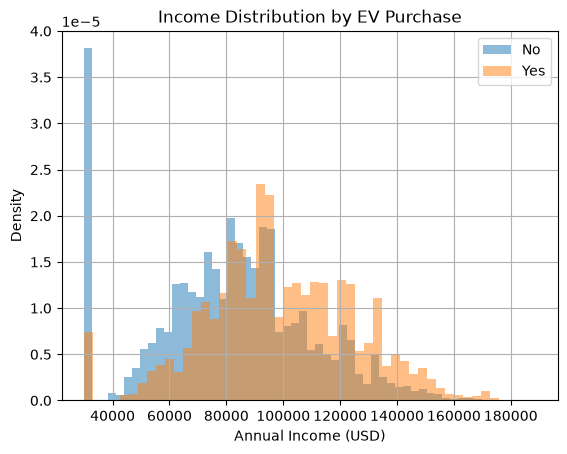

In [17]:
train[train["Will_Buy_EV"] == "No"]["Annual_Income_USD"].hist(
    bins=50,
    alpha=0.5,
    density=True,
    label="No"
)

train[train["Will_Buy_EV"] == "Yes"]["Annual_Income_USD"].hist(
    bins=50,
    alpha=0.5,
    density=True,
    label="Yes"
)

plt.xlabel("Annual Income (USD)")
plt.ylabel("Density")
plt.title("Income Distribution by EV Purchase")
plt.legend()
plt.show()

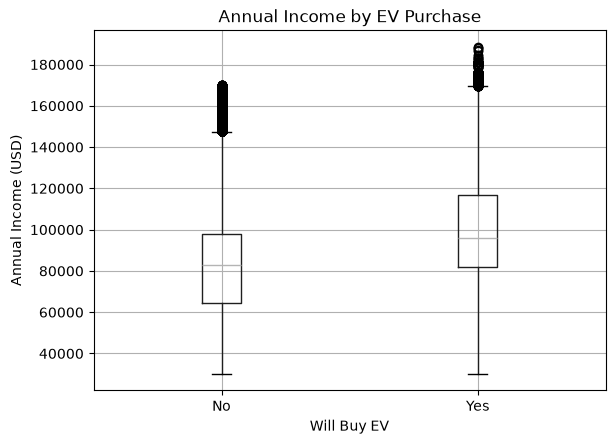

In [18]:

train.boxplot(
    column="Annual_Income_USD",
    by="Will_Buy_EV"
)

plt.title("Annual Income by EV Purchase")
plt.suptitle("")
plt.xlabel("Will Buy EV")
plt.ylabel("Annual Income (USD)")
plt.show()

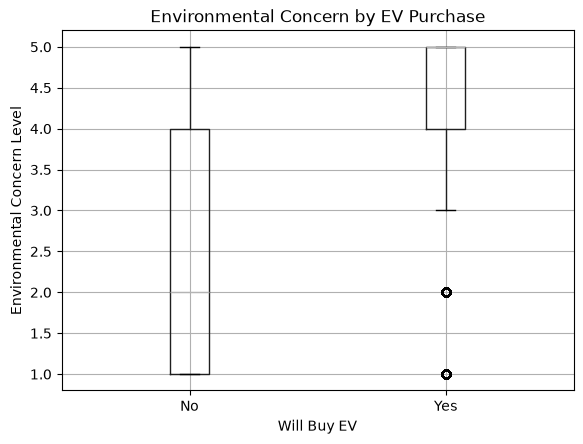

In [9]:
train.boxplot(
    column="Environmental_Concern_Level",
    by="Will_Buy_EV"
)

plt.title("Environmental Concern by EV Purchase")
plt.suptitle("")
plt.xlabel("Will Buy EV")
plt.ylabel("Environmental Concern Level")
plt.show()

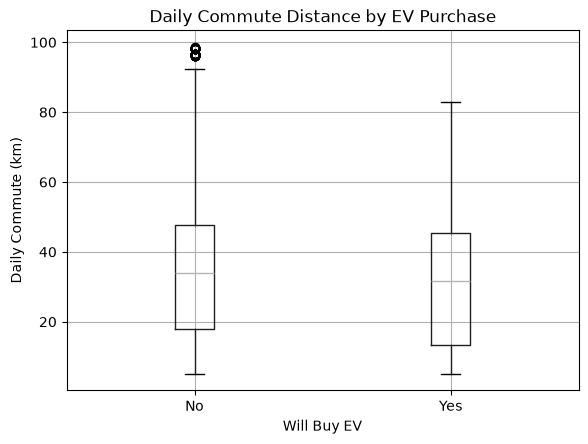

In [19]:
train.boxplot(
    column="Daily_Commute_km",
    by="Will_Buy_EV"
)

plt.title("Daily Commute Distance by EV Purchase")
plt.suptitle("")
plt.xlabel("Will Buy EV")
plt.ylabel("Daily Commute (km)")
plt.show()

## 5. Preprocessing

The target was converted to a binary variable. Numerical features were standardized and categorical variables were one-hot encoded using a shared preprocessing pipeline.

In [20]:
X = train.drop(columns=["id", "Will_Buy_EV"])

y = train["Will_Buy_EV"]
y = y.map({
    "No": 0,
    "Yes": 1
})
y.value_counts()

Will_Buy_EV
0    551886
1    116779
Name: count, dtype: int64

In [21]:
numerical_features = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level"
]

categorical_features = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

## 6. Logistic Regression Baseline

Logistic Regression was used as a simple baseline before testing more flexible tree-based models.

In [23]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [25]:
logistic_pipeline.fit(X_train, y_train)

y_valid_prob = logistic_pipeline.predict_proba(X_valid)[:, 1]

validation_auc = roc_auc_score(y_valid, y_valid_prob)

print("Validation ROC-AUC:", validation_auc)

Validation ROC-AUC: 0.9379578769118005


## 7. Cross-Validation

To obtain a more stable estimate of model performance, I used 5-fold stratified cross-validation and ROC-AUC as the evaluation metric.

In [26]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [27]:
logistic_scores = cross_val_score(
    logistic_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Logistic Regression CV scores:", logistic_scores)
print("Mean ROC-AUC:", logistic_scores.mean())
print("STD:", logistic_scores.std())

Logistic Regression CV scores: [0.93666942 0.93804484 0.93907142 0.93862534 0.93806707]
Mean ROC-AUC: 0.9380956156863736
STD: 0.0008087317757731136


## 8. Subsidy Sensitivity Check

Subsidy availability showed a particularly strong relationship with the target. To check how dependent the baseline model was on this feature, I repeated cross-validation after removing it.

In [28]:
X_no_subsidy = X.drop(columns=["Subsidy_Available"])

categorical_features_no_subsidy = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Range_Anxiety_Level"
]

In [29]:
preprocessor_no_subsidy = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_no_subsidy
        )
    ]
)

In [30]:
logistic_no_subsidy = Pipeline([
    ("preprocessor", preprocessor_no_subsidy),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [31]:
scores_no_subsidy = cross_val_score(
    logistic_no_subsidy,
    X_no_subsidy,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Without Subsidy CV scores:", scores_no_subsidy)
print("Without Subsidy Mean ROC-AUC:", scores_no_subsidy.mean())
print("Without Subsidy STD:", scores_no_subsidy.std())

Without Subsidy CV scores: [0.88011946 0.88288703 0.88298048 0.88345779 0.88190395]
Without Subsidy Mean ROC-AUC: 0.8822697409041662
Without Subsidy STD: 0.001187866898374063


In [32]:
pd.crosstab(
    X["Subsidy_Available"],
    y,
    normalize="index"
)

Will_Buy_EV,0,1
Subsidy_Available,,
No,0.994243,0.005757
Yes,0.725305,0.274695


Removing subsidy availability reduced mean ROC-AUC substantially, indicating that it is an important predictive feature, although the model still retained meaningful predictive performance without it.

## 9. Model Comparison

I compared Logistic Regression with Random Forest and XGBoost using the same cross-validation setup.

In [33]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [34]:
rf_scores = cross_val_score(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Random Forest CV scores:", rf_scores)
print("Random Forest Mean ROC-AUC:", rf_scores.mean())
print("Random Forest STD:", rf_scores.std())

Random Forest CV scores: [0.93226338 0.93358024 0.93451368 0.93379566 0.93334414]
Random Forest Mean ROC-AUC: 0.9334994193415763
Random Forest STD: 0.0007314252957070454


In [35]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        eval_metric="logloss"
    ))
])

In [36]:
xgb_scores = cross_val_score(
    xgb_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("XGBoost CV scores:", xgb_scores)
print("XGBoost Mean ROC-AUC:", xgb_scores.mean())
print("XGBoost STD:", xgb_scores.std())

XGBoost CV scores: [0.93965903 0.94076835 0.94194849 0.94157547 0.94089164]
XGBoost Mean ROC-AUC: 0.9409685991921288
XGBoost STD: 0.0007860622970993366


In [ ]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Mean ROC-AUC": [
        logistic_scores.mean(),
        rf_scores.mean(),
        xgb_scores.mean()
    ],
    "STD": [
        logistic_scores.std(),
        rf_scores.std(),
        xgb_scores.std()
    ]
})

model_results

,Model,Mean ROC-AUC,STD
0,Logistic Regression,0.938096,0.000809
1,Random Forest,0.933499,0.000731
2,XGBoost,0.940969,0.000786


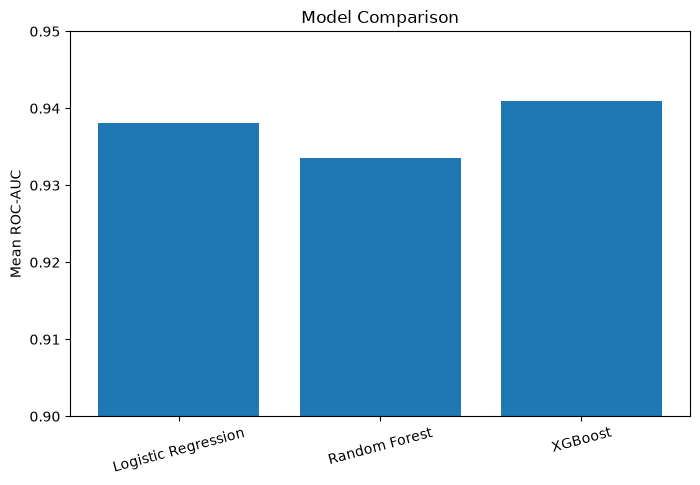

In [38]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["Mean ROC-AUC"]
)

plt.ylabel("Mean ROC-AUC")
plt.title("Model Comparison")
plt.ylim(0.90, 0.95)
plt.xticks(rotation=15)

plt.show()

## 10. Final XGBoost Model

XGBoost achieved the highest cross-validated ROC-AUC, so it was selected as the final model for interpretation and test-set prediction.

In [39]:
xgb_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','Annual_Income_USD','Daily_Commute_km',...,'Home_Charging_Possible', 'Subsidy_Available','Range_Anxiety_Level']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop

## 11. Feature Importance

In [40]:
feature_names = (
    xgb_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    xgb_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance_df["Importance_%"] = (
    feature_importance_df["Importance"]
    / feature_importance_df["Importance"].sum()
    * 100
)

feature_importance_df.head(10)

,Feature,Importance,Importance_%
19,cat__Subsidy_Available_No,0.645473,64.547333
6,num__Environmental_Concern_Level,0.284380,28.438028
22,cat__Range_Anxiety_Level_Low,0.023946,2.394637
1,num__Annual_Income_USD,0.019982,1.998191
17,cat__Home_Charging_Possible_No,0.004726,0.472642
2,num__Daily_Commute_km,0.003418,0.341798
21,cat__Range_Anxiety_Level_High,0.003277,0.327655
0,num__Age,0.002048,0.204795
4,num__Charging_Stations_Near_Home,0.001414,0.141412
23,cat__Range_Anxiety_Level_Medium,0.001284,0.128448


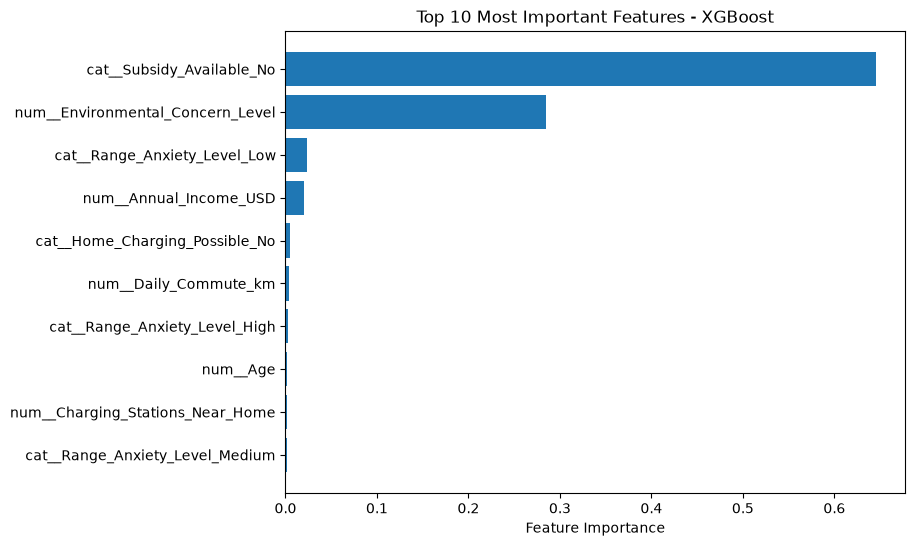

In [41]:
top10 = (
    feature_importance_df
    .head(10)
    .sort_values("Importance")
)

plt.figure(figsize=(8, 6))

plt.barh(
    top10["Feature"],
    top10["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Most Important Features - XGBoost")

plt.show()

## 12. SHAP Analysis

SHAP was used to examine both the relative importance of features and the direction of their contribution to model predictions.

In [42]:
X_transformed = (
    xgb_pipeline
    .named_steps["preprocessor"]
    .transform(X)
)

xgb_model = xgb_pipeline.named_steps["classifier"]

In [43]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(
    X_transformed
)

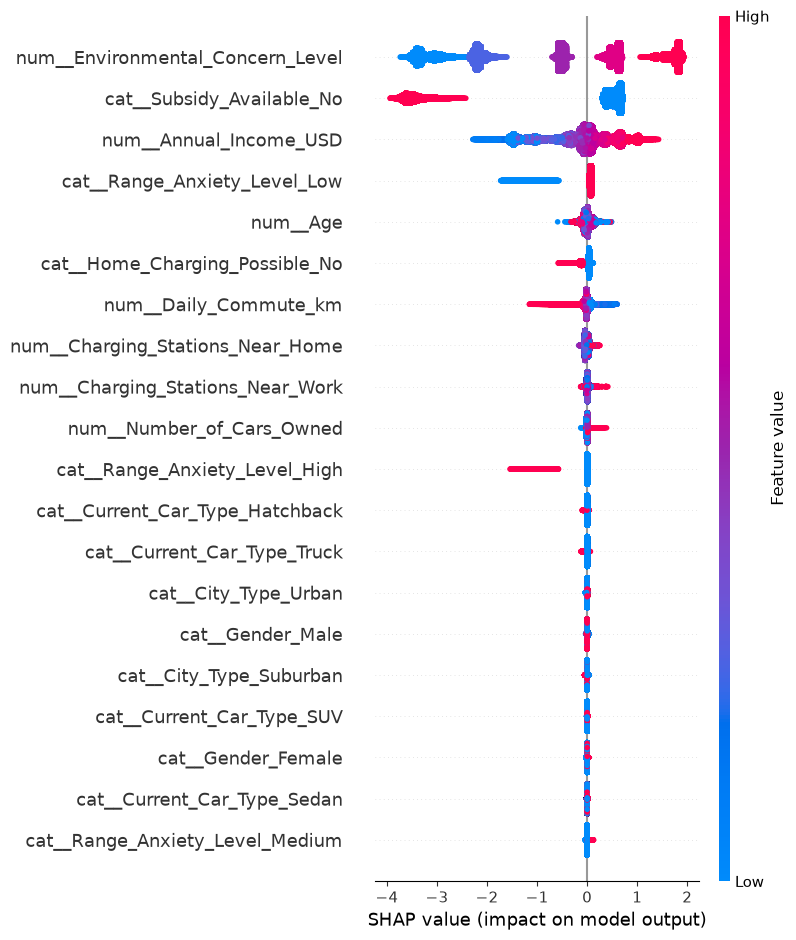

In [44]:
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names
)

The SHAP analysis suggests that environmental concern, subsidy availability, annual income, range anxiety, and home charging access were among the most influential predictive factors.

Higher environmental concern and income generally pushed predictions toward EV purchase, while high range anxiety and lack of home charging access reduced predicted purchase likelihood.

## 13. Kaggle Submission

In [45]:
test_X = test[X.columns]

test_prob = xgb_pipeline.predict_proba(test_X)[:, 1]

In [46]:
submission = sample_submission.copy()
submission["Will_Buy_EV"] = test_prob
submission.head()

,id,Will_Buy_EV
0,668665,0.008436
1,668666,0.017951
2,668667,0.006480
3,668668,0.003891
4,668669,0.018227


In [47]:
submission.to_csv(
    "submission.csv",
    index=False
)

## 14. Conclusion

XGBoost achieved the best cross-validated ROC-AUC of approximately 0.941, slightly outperforming Logistic Regression.

The results suggest that environmental attitudes, financial incentives, income, range anxiety, and charging accessibility are particularly useful for predicting EV purchase intention.